## 0. Configuration

In [ ]:
QUICK = False                        

SEEDS = [0] if QUICK else [0, 1, 2]   

CFG = dict(
    backbone="vit_base_patch14_dinov2.lvd142m",   
    weights_file=None,        
    pretrained=True,
    cache_size=256, crop=224, lora_r=8,
    bs=16, eval_bs=64, lr_lora=5e-4, lr_head=1e-3, wd=1e-4,
    legacy_epochs=4 if QUICK else 20, legacy_patience=5,
    epochs=4 if QUICK else 30, patience=6,
    kd_lambda=1.0, fd_alpha=1.0, fd_beta=5.0,              
    pc_lambda=1.0, pc_kappa=2.0, pc_wpos=2.0, aux_lambda=0.5,   
    gate_mag=1.5, gate_tau=0.5, gate_beta=0.5,              
    fallback_p=0.8, wise_alpha=0.5,
    cross_thr=5, remove_v2_internal=True,                   
)

TRAINED = ["FT", "KD", "FD", "CURE", "CURE-noPC", "CURE-noPrior", "CURE-noGate", "Joint"]


## 1. Setup

In [5]:
import json, sys, time, copy
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from IPython.display import display

PROJECT_ROOT = Path.cwd() if (Path.cwd() / "src").is_dir() else Path.cwd().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
from src import config, audit, cure

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
OUT = config.OUTPUT_DIR
CACHE, CKPT, RES = OUT / "cache", OUT / "checkpoints", OUT / "results"
for d in (CACHE, CKPT, RES):
    d.mkdir(parents=True, exist_ok=True)
RUNS_FILE = RES / ("runs_quick.jsonl" if QUICK else "runs.jsonl")
print("device:", DEVICE, torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "")
print("torch", torch.__version__)

device: cuda NVIDIA GeForce RTX 4060
torch 2.11.0+cu128


## 2. Manifests and label spaces (from notebook 01)

In [ ]:
M = config.MANIFEST_DIR
man1 = {s: pd.read_csv(M / f"rfmid1_{s}.csv", dtype={"ID": str}) for s in config.SPLITS}
man2 = {s: pd.read_csv(M / f"rfmid2_{s}.csv", dtype={"ID": str}) for s in config.SPLITS}
space = json.load(open(M / "label_space.json"))

classes1 = space["rfmid1_classes"]                     
new2 = space["new"]                                      
UNION = classes1 + new2                                 
N_OLD = len(classes1)
shared_map = space["shared_map"]                         
SH = [UNION.index(c) for c in shared_map]              
RT = [UNION.index(c) for c in space["retired"]]          
NW = list(range(N_OLD, len(UNION)))                      
OLD = list(range(N_OLD))
print(f"union {len(UNION)} = shared {len(SH)} + retired {len(RT)} + new {len(NW)}")

union 57 = shared 38 + retired 7 + new 12


## 3. Overlap audit and image cache

In [7]:
t0 = time.time()
all1 = pd.concat(man1.values(), ignore_index=True)
all2 = pd.concat(man2.values(), ignore_index=True)
print("fingerprinting + caching RFMiD 1.0 ...")
fp1 = audit.fingerprint_and_cache(all1, CACHE / "rfmid1", CFG["cache_size"], CACHE / "fingerprints_rfmid1.csv")
print("fingerprinting + caching RFMiD 2.0 ...")
fp2 = audit.fingerprint_and_cache(all2, CACHE / "rfmid2", CFG["cache_size"], CACHE / "fingerprints_rfmid2.csv")
print(f"done in {(time.time() - t0) / 60:.1f} min")

drops, audit_summary = audit.run_audit(fp1, fp2, CFG["cross_thr"], CFG["remove_v2_internal"])
drops.to_csv(RES / "audit_removed_rfmid2.csv", index=False)
drop_keys = set(zip(drops["split"], drops["ID"]))
clean2 = {s: m[[(s, i) not in drop_keys for i in m["ID"]]].reset_index(drop=True) for s, m in man2.items()}

print(json.dumps(audit_summary, indent=1))
print("removed by reason:", drops["reason"].value_counts().to_dict())
print("RFMiD 2.0 after audit:", {s: len(m) for s, m in clean2.items()})

fingerprinting + caching RFMiD 1.0 ...
    200/3200
    400/3200
    600/3200
    800/3200
    1000/3200
    1200/3200
    1400/3200
    1600/3200
    1800/3200
    2000/3200
    2200/3200
    2400/3200
    2600/3200
    2800/3200
    3000/3200
    3200/3200
fingerprinting + caching RFMiD 2.0 ...
    200/854
    400/854
    600/854
    800/854
done in 7.4 min
{
 "within_2.0_byte_duplicates": 3,
 "cross_version_H<=0": {
  "train": 0,
  "val": 0,
  "test": 1
 },
 "cross_version_H<=3": {
  "train": 10,
  "val": 4,
  "test": 3
 },
 "cross_version_H<=5": {
  "train": 55,
  "val": 15,
  "test": 17
 },
 "cross_version_H<=8": {
  "train": 159,
  "val": 55,
  "test": 55
 },
 "within_2.0_train_vs_eval_H<=5": {
  "val": 5,
  "test": 11
 },
 "within_2.0_internal_removed": true
}
removed by reason: {'near-duplicate of RFMiD 1.0 train (H<=5)': 87, 'near-duplicate of a 2.0 training image': 16, 'byte-identical duplicate within 2.0': 3}
RFMiD 2.0 after audit: {'train': 452, 'val': 157, 'test': 139}


## 4. Images and labels in memory

In [8]:
def label_arrays(man, dataset):
    """Labels in UNION space; mask = 1 where the label is known for this dataset."""
    n = len(man)
    Y = np.zeros((n, len(UNION)), dtype=np.float32)
    Mk = np.zeros_like(Y)
    if dataset == "rfmid1":
        Y[:, OLD] = man[classes1].values
        Mk[:, OLD] = 1
    else:
        for c1, c2 in shared_map.items():
            j = UNION.index(c1)
            Y[:, j], Mk[:, j] = man[c2].values, 1
        for c2 in new2:
            j = UNION.index(c2)
            Y[:, j], Mk[:, j] = man[c2].values, 1
    return torch.from_numpy(Y), torch.from_numpy(Mk)

def split_data(man, dataset):
    paths = [CACHE / dataset / f"{s}_{i}.jpg" for s, i in zip(man["split"], man["ID"])]
    Y, Mk = label_arrays(man, dataset)
    return {"X": cure.load_cache(paths), "Y": Y, "M": Mk}

t0 = time.time()
D1 = {s: split_data(m, "rfmid1") for s, m in man1.items()}
D2 = {s: split_data(m, "rfmid2") for s, m in clean2.items()}
print({f"v1_{s}": len(d["X"]) for s, d in D1.items()}, {f"v2_{s}": len(d["X"]) for s, d in D2.items()})
print(f"loaded in {time.time() - t0:.0f}s")

# Evaluation groups on the RFMiD 2.0 test set
hr = UNION.index("HR") if "HR" in UNION else None
GROUPS = {"shared": SH, "new": NW, "all": SH + NW,
          "all_exHR": [c for c in SH + NW if c != hr]}
Yv, Mv = D2["val"]["Y"].numpy(), D2["val"]["M"].numpy()
Yt, Mt = D2["test"]["Y"].numpy(), D2["test"]["M"].numpy()
Y1t, M1t = D1["test"]["Y"].numpy(), D1["test"]["M"].numpy()

{'v1_train': 1920, 'v1_val': 640, 'v1_test': 640} {'v2_train': 452, 'v2_val': 157, 'v2_test': 139}
loaded in 23s


## 5. Experiments

In [9]:
def done_runs():
    if not RUNS_FILE.exists():
        return set()
    return {(r["method"], r["seed"]) for r in map(json.loads, RUNS_FILE.read_text().splitlines())}

def record(row):
    with open(RUNS_FILE, "a") as f:
        f.write(json.dumps(row) + "\n")

def pad_union(l45):
    return np.concatenate([l45, np.zeros((len(l45), len(UNION) - N_OLD), dtype=l45.dtype)], 1)

def fresh_backbone():
    return cure.build_backbone(CFG["backbone"], CFG["pretrained"], CFG["crop"], CFG["lora_r"], CFG["weights_file"])

def v1_retention(logits_v1test):
    return cure.macro_ap(logits_v1test, Y1t, M1t, OLD)

def finish(method, seed, l_val, l_test, l_v1test, legacy_pack, passes, secs, extra=None, thr=None):
    if (method, seed) in done_runs():                      # already recorded (resumed run)
        return None
    leg_thr_union = legacy_pack["thr_union"]
    if thr is None:                                        # operating thresholds tuned on 2.0 validation
        thr = cure.f1_thresholds(l_val, Yv, Mv, fallback=np.where(np.arange(len(UNION)) < N_OLD, leg_thr_union, 0.5))
    res = cure.evaluate(l_test, thr, legacy_pack["l_test"], leg_thr_union, Yt, Mt, GROUPS, SH)
    res.update(method=method, seed=seed, mAP_v1_retention=v1_retention(l_v1test),
               backbone_passes=passes, train_min=round(secs / 60, 1))
    if method.startswith("Legacy"):                         # legacy cannot predict 2.0-only classes
        res.update({"mAP_new": float("nan"), "mAP_all": float("nan"), "mAP_all_exHR": float("nan")})
    if extra:
        res.update(extra)
    pc = cure.per_class_ap(l_test, Yt, Mt, SH + NW)
    res["per_class_ap"] = {UNION[c]: (None if np.isnan(v) else round(v, 4)) for c, v in pc.items()}
    record(res)
    print(f"  {method:15s} mAP_all {res['mAP_all']:.4f}  NFR {res['NFR_%']:.2f}%  NFR+ {res['NFR+_%']:.2f}%  "
          f"regressed {res['regressed_classes']}  v1-retention {res['mAP_v1_retention']:.4f}")
    return res

In [10]:
def legacy_for_seed(seed):
    """Train (or reload) the RFMiD 1.0 model; return it with its logits and thresholds."""
    cure.set_seed(seed)
    net = cure.Net(fresh_backbone(), N_OLD)
    for n_, p in net.backbone.named_parameters():
        p.requires_grad = n_.endswith(".A") or n_.endswith(".B")
    ck = CKPT / f"legacy_seed{seed}{'_quick' if QUICK else ''}.pt"
    if ck.exists():
        net.load_trainable(torch.load(ck, map_location="cpu"))
        net.to(DEVICE)
        print(f"  legacy: loaded {ck.name}")
    else:
        t0 = time.time()
        cfg = dict(CFG, epochs=CFG["legacy_epochs"], patience=CFG["legacy_patience"])
        tr = {k: (v[:, :N_OLD] if k != "X" else v) for k, v in D1["train"].items()}
        va = {k: (v[:, :N_OLD] if k != "X" else v) for k, v in D1["val"].items()}
        cure.train(net, None, "legacy", tr, va, {}, cfg, DEVICE, OLD)
        torch.save(net.trainable_state(), ck)
        print(f"  legacy trained in {(time.time() - t0) / 60:.1f} min")
    for p in net.parameters():
        p.requires_grad = False
    net.eval()
    P = lambda X: cure.predict(net, None, X, "legacy", {}, CFG, DEVICE)
    pack = {"net": net}
    pack["l_v1val"], pack["l_v1test"] = P(D1["val"]["X"]), P(D1["test"]["X"])
    for s in ("train", "val", "test"):
        pack[f"l_{s}"] = pad_union(P(D2[s]["X"]))
    thr45 = cure.f1_thresholds(pack["l_v1val"], D1["val"]["Y"].numpy()[:, :N_OLD], D1["val"]["M"].numpy()[:, :N_OLD], np.full(N_OLD, 0.5))
    pack["thr_union"] = np.concatenate([thr45, np.full(len(UNION) - N_OLD, 0.5)])
    pack["l_v1test_union"] = pad_union(pack["l_v1test"])
    return pack


def run_update(method, seed, legacy_pack):
    cure.set_seed(seed)
    t0 = time.time()
    legacy = legacy_pack["net"]
    thr_logit = torch.tensor(cure.logit(legacy_pack["thr_union"]), dtype=torch.float32, device=DEVICE)
    ctx = {"shared_idx": SH, "retired_idx": RT, "old_idx": OLD, "thr_logit": thr_logit}

    if method == "Joint":                                   # upper bound: fresh model, 1.0 + 2.0 data
        net = cure.Net(fresh_backbone(), len(UNION))
        for n_, p in net.backbone.named_parameters():
            p.requires_grad = n_.endswith(".A") or n_.endswith(".B")
        tr = {k: torch.cat([D1["train"][k], D2["train"][k]]) for k in ("X", "Y", "M")}
        train_method = "FT"
    else:
        net = cure.expand_from_legacy(legacy, len(UNION), N_OLD)
        tr, train_method = D2["train"], method
    init_state = net.trainable_state()

    info = {}
    if method in ("CURE", "CURE-noPC"):                     # gate prior from separability retention
        prior, ratios = cure.gate_prior(legacy_pack["l_v1val"], D1["val"]["Y"].numpy(), legacy_pack["l_train"],
                                        D2["train"]["Y"].numpy(), D2["train"]["M"].numpy(), SH,
                                        CFG["gate_tau"], CFG["gate_beta"], CFG["gate_mag"])
        with torch.no_grad():
            for c, v in prior.items():
                net.decoder.beta[c] = v
        info = {"gate_prior_counts": {"legacy": sum(v < 0 for v in prior.values()),
                                      "update": sum(v > 0 for v in prior.values()),
                                      "neutral": sum(v == 0 for v in prior.values())}}

    cure.train(net, legacy, train_method, tr, D2["val"], ctx, CFG, DEVICE, SH + NW)
    P = lambda X: cure.predict(net, legacy, X, train_method, ctx, CFG, DEVICE)
    l_val, l_test, l_v1 = P(D2["val"]["X"]), P(D2["test"]["X"]), P(D1["test"]["X"])
    secs = time.time() - t0
    passes = 2 if method in cure.GATED else 1
    out = {"net": net, "init_state": init_state, "l_val": l_val, "l_test": l_test, "l_v1": l_v1}

    if method == "CURE":                                    # part 3: non-inferiority fallback
        finish("CURE-noFallback", seed, l_val, l_test, l_v1, legacy_pack, passes, secs, info)
        fall = cure.noninferiority_fallback(l_val, legacy_pack["l_val"], Yv, Mv, SH, p_worse=CFG["fallback_p"], seed=seed)
        for L, Lg in ((l_val, legacy_pack["l_val"]), (l_test, legacy_pack["l_test"]), (l_v1, legacy_pack["l_v1test_union"])):
            L[:, fall] = Lg[:, fall]
        info["fallback_classes"] = [UNION[c] for c in fall]
    finish(method, seed, l_val, l_test, l_v1, legacy_pack, passes, secs, info)
    return out

In [11]:
NEEDS = {"FT": ["FT", "WiSE", "OE", "Select"], "CURE": ["CURE", "CURE-noFallback"]}

for seed in SEEDS:
    print(f"\n=== seed {seed} ===")
    pack = legacy_for_seed(seed)
    # Legacy as deployed (RFMiD 1.0 thresholds; NFR = 0 by definition) and with thresholds re-tuned on 2.0 val
    finish("Legacy", seed, pack["l_val"], pack["l_test"], pack["l_v1test_union"], pack, 1, 0, thr=pack["thr_union"])
    finish("Legacy-recal", seed, pack["l_val"], pack["l_test"], pack["l_v1test_union"], pack, 1, 0)

    for method in TRAINED:
        done = done_runs()
        if all((m, seed) in done for m in NEEDS.get(method, [method])):
            continue
        print(f"  training {method} ...")
        out = run_update(method, seed, pack)

        if method == "FT":                                  # derived from FT: no extra training
            w = cure.wise_interpolate(out["net"], out["init_state"], CFG["wise_alpha"], N_OLD)
            P = lambda X: cure.predict(w, None, X, "FT", {}, CFG, DEVICE)
            finish("WiSE", seed, P(D2["val"]["X"]), P(D2["test"]["X"]), P(D1["test"]["X"]), pack, 1, 0)
            finish("OE", seed, cure.output_ensemble(out["l_val"], pack["l_val"], N_OLD),
                   cure.output_ensemble(out["l_test"], pack["l_test"], N_OLD),
                   cure.output_ensemble(out["l_v1"], pack["l_v1test_union"], N_OLD), pack, 2, 0)
            sel_args = (out["l_val"], pack["l_val"], Yv, Mv)
            lv, _ = cure.per_class_select(*sel_args, out["l_val"], pack["l_val"], SH, RT)
            lt, chose = cure.per_class_select(*sel_args, out["l_test"], pack["l_test"], SH, RT)
            l1, _ = cure.per_class_select(*sel_args, out["l_v1"], pack["l_v1test_union"], SH, RT)
            finish("Select", seed, lv, lt, l1, pack, 2, 0,
                   {"select_legacy_classes": sum(v == "legacy" for v in chose.values())})
            del w
        del out
        if DEVICE.type == "cuda":
            torch.cuda.empty_cache()
    del pack


=== seed 0 ===


c:\Users\Sajjad\.conda\envs\pytorch_gpu\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


    ep 01  loss 1.054  val mAP 0.2340  (17s)
    ep 02  loss 0.818  val mAP 0.2770  (16s)
    ep 03  loss 0.700  val mAP 0.3113  (16s)
    ep 04  loss 0.622  val mAP 0.3399  (16s)
    ep 05  loss 0.547  val mAP 0.3548  (16s)
    ep 06  loss 0.497  val mAP 0.4150  (16s)
    ep 07  loss 0.429  val mAP 0.3786  (16s)
    ep 08  loss 0.374  val mAP 0.3993  (16s)
    ep 09  loss 0.320  val mAP 0.4090  (16s)
    ep 10  loss 0.265  val mAP 0.3973  (16s)
    ep 11  loss 0.214  val mAP 0.4015  (16s)
  legacy trained in 2.9 min
  Legacy          mAP_all nan  NFR 0.00%  NFR+ 0.00%  regressed 0  v1-retention 0.3782
  Legacy-recal    mAP_all nan  NFR 14.65%  NFR+ 6.45%  regressed 0  v1-retention 0.3782
  training FT ...
    ep 01  loss 1.509  val mAP 0.3536  (4s)
    ep 02  loss 0.959  val mAP 0.4005  (4s)
    ep 03  loss 0.783  val mAP 0.4408  (4s)
    ep 04  loss 0.640  val mAP 0.4210  (4s)
    ep 05  loss 0.564  val mAP 0.4603  (4s)
    ep 06  loss 0.479  val mAP 0.4711  (4s)
    ep 07  loss 0.37

c:\Users\Sajjad\Documents\Documents\paper-1\paper-1\src\cure.py:336: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  sched.step()


    ep 01  loss 2.384  val mAP 0.2482  (6s)
    ep 02  loss 2.297  val mAP 0.2951  (6s)
    ep 03  loss 1.931  val mAP 0.3308  (6s)
    ep 04  loss 1.647  val mAP 0.3476  (6s)
    ep 05  loss 1.497  val mAP 0.3833  (6s)
    ep 06  loss 1.374  val mAP 0.3714  (6s)
    ep 07  loss 1.318  val mAP 0.4071  (6s)
    ep 08  loss 1.064  val mAP 0.3875  (6s)
    ep 09  loss 0.872  val mAP 0.3970  (6s)
    ep 10  loss 0.756  val mAP 0.4323  (6s)
    ep 11  loss 0.727  val mAP 0.3942  (6s)
    ep 12  loss 0.554  val mAP 0.4106  (6s)
    ep 13  loss 0.496  val mAP 0.3653  (6s)
    ep 14  loss 0.377  val mAP 0.3834  (6s)
    ep 15  loss 0.339  val mAP 0.3924  (6s)
    ep 16  loss 0.303  val mAP 0.4026  (6s)
  CURE-noGate     mAP_all 0.4075  NFR 6.02%  NFR+ 9.68%  regressed 7  v1-retention 0.2739
  training Joint ...
    ep 01  loss 1.107  val mAP 0.2928  (18s)
    ep 02  loss 0.892  val mAP 0.3205  (18s)
    ep 03  loss 0.760  val mAP 0.4010  (18s)
    ep 04  loss 0.680  val mAP 0.3673  (18s)
    e

c:\Users\Sajjad\Documents\Documents\paper-1\paper-1\src\cure.py:336: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  sched.step()


... (7 outputs left out)

c:\Users\Sajjad\Documents\Documents\paper-1\paper-1\src\cure.py:336: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  sched.step()


    ep 01  loss 3.460  val mAP 0.2852  (6s)
    ep 02  loss 2.563  val mAP 0.3122  (6s)
    ep 03  loss 2.221  val mAP 0.2973  (6s)
    ep 04  loss 1.999  val mAP 0.3147  (6s)
    ep 05  loss 1.777  val mAP 0.3553  (6s)
    ep 06  loss 1.693  val mAP 0.3757  (6s)
    ep 07  loss 1.555  val mAP 0.3381  (6s)
    ep 08  loss 1.535  val mAP 0.3821  (6s)
    ep 09  loss 1.332  val mAP 0.3834  (6s)
    ep 10  loss 1.198  val mAP 0.3555  (6s)
    ep 11  loss 1.159  val mAP 0.3659  (6s)
    ep 12  loss 1.196  val mAP 0.3826  (6s)
    ep 13  loss 1.056  val mAP 0.3646  (6s)
    ep 14  loss 0.941  val mAP 0.3593  (6s)
    ep 15  loss 0.912  val mAP 0.3693  (6s)
  CURE-noPrior    mAP_all 0.3536  NFR 5.00%  NFR+ 9.03%  regressed 2  v1-retention 0.3615
  training CURE-noGate ...


c:\Users\Sajjad\Documents\Documents\paper-1\paper-1\src\cure.py:336: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  sched.step()


    ep 01  loss 2.656  val mAP 0.2925  (6s)
    ep 02  loss 2.310  val mAP 0.3217  (6s)
    ep 03  loss 1.905  val mAP 0.3430  (6s)
    ep 04  loss 1.688  val mAP 0.3836  (6s)
    ep 05  loss 1.475  val mAP 0.4013  (6s)
    ep 06  loss 1.348  val mAP 0.3766  (6s)
    ep 07  loss 1.115  val mAP 0.3970  (6s)
    ep 08  loss 1.054  val mAP 0.4216  (6s)
    ep 09  loss 0.929  val mAP 0.4202  (6s)
    ep 10  loss 0.744  val mAP 0.4175  (6s)
    ep 11  loss 0.639  val mAP 0.4010  (6s)
    ep 12  loss 0.564  val mAP 0.4180  (6s)
    ep 13  loss 0.530  val mAP 0.4117  (6s)
    ep 14  loss 0.400  val mAP 0.4783  (6s)
    ep 15  loss 0.344  val mAP 0.4399  (6s)
    ep 16  loss 0.351  val mAP 0.4205  (6s)
    ep 17  loss 0.210  val mAP 0.4169  (6s)
    ep 18  loss 0.231  val mAP 0.4254  (6s)
    ep 19  loss 0.134  val mAP 0.4666  (6s)
    ep 20  loss 0.091  val mAP 0.4771  (6s)
  CURE-noGate     mAP_all 0.4326  NFR 5.96%  NFR+ 12.26%  regressed 3  v1-retention 0.2741
  training Joint ...
    ep 0

## 6. Results

,mAP_all,mAP_shared,mAP_new,NFR_%,NFR+_%,regressed_classes,mAP_v1_retention,backbone_passes
method,,,,,,,,
Legacy,nan,0.2263 ± 0.0203,nan,0.0000 ± 0.0000,0.0000 ± 0.0000,0.0000 ± 0.0000,0.3995 ± 0.0229,1.0000 ± 0.0000
Legacy-recal,nan,0.2263 ± 0.0203,nan,10.6778 ± 3.7464,8.3871 ± 1.7069,0.0000 ± 0.0000,0.3995 ± 0.0229,1.0000 ± 0.0000
FT,0.4384 ± 0.0232,0.3729 ± 0.0308,0.7084 ± 0.1233,6.7083 ± 2.0218,13.5484 ± 2.3262,5.0000 ± 2.6458,0.2648 ± 0.0342,1.0000 ± 0.0000
KD,0.4410 ± 0.0231,0.4023 ± 0.0365,0.6010 ± 0.0551,7.7685 ± 0.5649,11.3978 ± 2.6074,3.6667 ± 0.5774,0.2857 ± 0.0088,1.0000 ± 0.0000
FD,0.4535 ± 0.0333,0.4124 ± 0.0304,0.6228 ± 0.0480,7.6739 ± 1.0685,9.8925 ± 2.6074,3.6667 ± 1.5275,0.2924 ± 0.0318,1.0000 ± 0.0000
WiSE,0.4092 ± 0.0236,0.3741 ± 0.0238,0.5539 ± 0.0747,6.1782 ± 0.8535,8.6022 ± 3.1825,1.6667 ± 0.5774,0.3757 ± 0.0234,1.0000 ± 0.0000
OE,0.4434 ± 0.0112,0.3792 ± 0.0312,0.7084 ± 0.1233,5.6544 ± 0.6721,8.8172 ± 0.7450,2.3333 ± 2.3094,0.3843 ± 0.0295,2.0000 ± 0.0000
Select,0.4277 ± 0.0252,0.3596 ± 0.0169,0.7084 ± 0.1233,4.7331 ± 0.5951,12.4731 ± 0.7450,3.3333 ± 1.5275,0.3163 ± 0.0291,2.0000 ± 0.0000
Joint,0.4532 ± 0.0035,0.4107 ± 0.0132,0.6284 ± 0.0727,6.3234 ± 1.3023,11.6129 ± 3.4139,3.6667 ± 2.3094,0.4054 ± 0.0065,1.0000 ± 0.0000


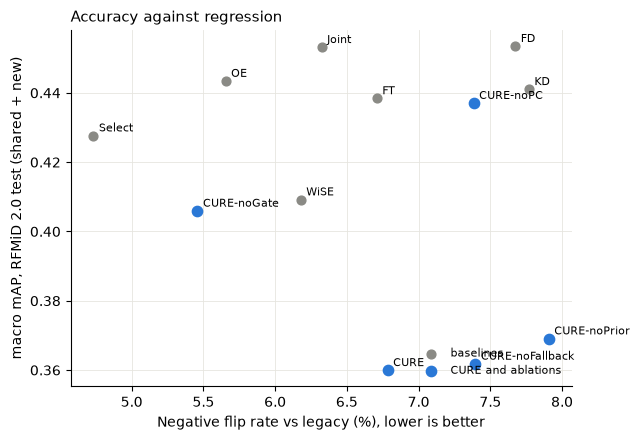

In [12]:
rows = [json.loads(l) for l in RUNS_FILE.read_text().splitlines()]
df = pd.DataFrame(rows)
df = df[df["seed"].isin(SEEDS)]
KEYS = ["mAP_all", "mAP_shared", "mAP_new", "mAP_all_exHR", "NFR_%", "NFR+_%", "PFR_%",
        "regressed_classes", "mAP_v1_retention", "backbone_passes", "train_min"]
ORDER = ["Legacy", "Legacy-recal", "FT", "KD", "FD", "WiSE", "OE", "Select", "Joint",
         "CURE", "CURE-noFallback", "CURE-noPC", "CURE-noPrior", "CURE-noGate"]
mean = df.groupby("method")[KEYS].mean().reindex([m for m in ORDER if m in set(df["method"])])
sd = df.groupby("method")[KEYS].std().reindex(mean.index)
fmt = lambda m, s: "nan" if pd.isna(m) else (f"{m:.4f}" if pd.isna(s) else f"{m:.4f} ± {s:.4f}")
table = pd.DataFrame({k: [fmt(m, s) for m, s in zip(mean[k], sd[k])] for k in KEYS}, index=mean.index)
table.to_csv(RES / "summary_table.csv")
display(table[["mAP_all", "mAP_shared", "mAP_new", "NFR_%", "NFR+_%", "regressed_classes", "mAP_v1_retention", "backbone_passes"]])

# Pareto view: accuracy vs regression (one point per method, mean over seeds)
fig, ax = plt.subplots(figsize=(6.5, 4.5))
base = [m for m in mean.index if not m.startswith("CURE") and m != "Legacy"]   # Legacy sits at NFR = 0
cur = [m for m in mean.index if m.startswith("CURE")]
ax.scatter(mean.loc[base, "NFR_%"], mean.loc[base, "mAP_all"], s=40, color="#8a8a85", label="baselines", zorder=3)
ax.scatter(mean.loc[cur, "NFR_%"], mean.loc[cur, "mAP_all"], s=55, color="#2a78d6", label="CURE and ablations", zorder=4)
for m in base + cur:
    ax.annotate(m, (mean.loc[m, "NFR_%"], mean.loc[m, "mAP_all"]), xytext=(4, 3), textcoords="offset points", fontsize=8)
ax.set_xlabel("Negative flip rate vs legacy (%), lower is better")
ax.set_ylabel("macro mAP, RFMiD 2.0 test (shared + new)")
ax.set_title("Accuracy against regression", loc="left", fontsize=11)
ax.grid(color="#e6e5df", lw=0.6)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, fontsize=8, loc="lower right")
fig.tight_layout()
fig.savefig(RES / "pareto_map_vs_nfr.png", dpi=200)
plt.show()

In [13]:
def m_(name, key):
    return float(mean.loc[name, key]) if name in mean.index else float("nan")

gates = {}
gates["G1_regression_exists"] = bool(m_("FT", "regressed_classes") >= 3)
nfr_floor = np.nanmin([m_(b, "NFR_%") for b in ("FT", "KD", "FD", "WiSE")])
gates["G2_less_regression_small_cost"] = bool((m_("CURE", "NFR_%") <= 0.7 * nfr_floor) and (m_("CURE", "mAP_all") >= m_("FT", "mAP_all") - 0.01))
gates["G3_beats_same_cost"] = bool(all(m_("CURE", "mAP_all") > m_(b, "mAP_all") and m_("CURE", "NFR_%") < m_(b, "NFR_%") for b in ("OE", "Select")))
abl = {a: bool(not (m_(a, "mAP_all") >= m_("CURE", "mAP_all") and m_(a, "NFR_%") <= m_("CURE", "NFR_%")))
       for a in ("CURE-noPC", "CURE-noPrior", "CURE-noGate", "CURE-noFallback") if a in mean.index}
gates["G4_components"] = abl

verdict = ("STOP: reframe" if not gates["G1_regression_exists"] else
           "GO" if gates["G2_less_regression_small_cost"] and gates["G3_beats_same_cost"] else "REVISE")

# paired CURE - baseline differences over seeds
paired = {}
piv = df.pivot_table(index="seed", columns="method", values=["mAP_all", "NFR_%"], dropna=False)
for b in ("Legacy-recal", "FT", "KD", "FD", "WiSE", "OE", "Select", "Joint"):
    if b in df["method"].values and "CURE" in df["method"].values:
        d_map = (piv["mAP_all"]["CURE"] - piv["mAP_all"][b]).dropna()
        d_nfr = (piv["NFR_%"]["CURE"] - piv["NFR_%"][b]).dropna()
        paired[b] = {"d_mAP": [round(d_map.mean(), 4), round(d_map.std(), 4)],
                     "d_NFR": [round(d_nfr.mean(), 2), round(d_nfr.std(), 2)]}

cure_rows = df[df["method"] == "CURE"]
send = {
    "quick_mode": QUICK, "seeds": SEEDS, "backbone": CFG["backbone"],
    "audit": {s: len(m) for s, m in clean2.items()} | {"removed": drops["reason"].value_counts().to_dict()},
    "means": mean[["mAP_all", "mAP_shared", "mAP_new", "mAP_all_exHR", "NFR_%", "NFR+_%", "regressed_classes",
                   "mAP_v1_retention", "backbone_passes"]].round(4).to_dict(orient="index"),
    "sd_mAP_all": sd["mAP_all"].round(4).to_dict(),
    "paired_CURE_minus": paired,
    "gates": gates, "verdict": verdict,
    "cure_fallback_classes": cure_rows["fallback_classes"].tolist() if "fallback_classes" in cure_rows else None,
    "cure_gate_prior": cure_rows["gate_prior_counts"].tolist() if "gate_prior_counts" in cure_rows else None,
}
(RES / ("summary_quick.json" if QUICK else "summary.json")).write_text(json.dumps(send, indent=1, default=str))
print("=" * 30, "SEND THIS BACK", "=" * 30)
print(json.dumps(send, default=str))

============================== SEND THIS BACK ==============================
{"quick_mode": false, "seeds": [0, 1, 2], "backbone": "vit_base_patch14_dinov2.lvd142m", "audit": {"train": 452, "val": 157, "test": 139, "removed": {"near-duplicate of RFMiD 1.0 train (H<=5)": 87, "near-duplicate of a 2.0 training image": 16, "byte-identical duplicate within 2.0": 3}}, "means": {"Legacy": {"mAP_all": NaN, "mAP_shared": 0.2263, "mAP_new": NaN, "mAP_all_exHR": NaN, "NFR_%": 0.0, "NFR+_%": 0.0, "regressed_classes": 0.0, "mAP_v1_retention": 0.3995, "backbone_passes": 1.0}, "Legacy-recal": {"mAP_all": NaN, "mAP_shared": 0.2263, "mAP_new": NaN, "mAP_all_exHR": NaN, "NFR_%": 10.6778, "NFR+_%": 8.3871, "regressed_classes": 0.0, "mAP_v1_retention": 0.3995, "backbone_passes": 1.0}, "FT": {"mAP_all": 0.4384, "mAP_shared": 0.3729, "mAP_new": 0.7084, "mAP_all_exHR": 0.4335, "NFR_%": 6.7083, "NFR+_%": 13.5484, "regressed_classes": 5.0, "mAP_v1_retention": 0.2648, "backbone_passes": 1.0}, "KD": {"mAP_all": 